# 01 — Auditoria inicial dos dados de voos

**Objetivo:** perceber o que foi descarregado, quantificar problemas e documentar as regras de preparação antes de treinar modelos.

Este notebook acompanha `scripts/audit_data.py`, que percorre os CSV em blocos e produz tabelas agregadas. Os dados originais não são alterados e nenhum modelo é treinado. O notebook apresenta os resultados; o script contém a lógica reutilizável.

**Perguntas:** os dois anos estão completos? Que campos têm valores ausentes? Quantos voos cumprem os critérios do enunciado? Os horários e campos redundantes são coerentes? Que variáveis poderão entrar num modelo pré-partida?

O enunciado é a fonte dos requisitos. A política de features adapta a auditoria documental anterior de 18/10/2026; trata-se de uma hipótese de admissibilidade temporal, não de importância preditiva demonstrada.


## 1. Preparar o ambiente e localizar os ficheiros

Requer Python 3.11+ e as dependências de `requirements-audit.txt`. Abrir o Jupyter na raiz do repositório ou em `notebooks/` e selecionar o kernel desse ambiente.

A localização por omissão dos dados é a pasta irmã `../dataset/`. Não usamos um caminho específico do computador do autor. É possível definir `FLIGHT_DATA_DIR` para outra localização. Os resultados volumosos ficam em `reports/generated/`, excluído do Git; este notebook guarda apenas tabelas e gráficos agregados nas suas saídas.


In [1]:
from pathlib import Path
import os
import sys
import json
import hashlib
import subprocess
import pandas as pd
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from IPython.display import display

candidates = [Path.cwd().resolve(), Path.cwd().resolve().parent]
ROOT = next((p for p in candidates if (p / "scripts/audit_data.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Abrir o notebook a partir da raiz do projeto ou de notebooks/.")
DATA_DIR = Path(os.environ.get("FLIGHT_DATA_DIR", str(ROOT.parent / "dataset"))).expanduser().resolve()
REPORTS = Path(os.environ.get("AUDIT_OUTPUT_DIR", str(ROOT / "reports/generated/data_audit"))).expanduser().resolve()
FILES = [DATA_DIR / "flights_2022.csv", DATA_DIR / "flights_2023.csv"]
assert all(p.is_file() for p in FILES), f"Faltam ficheiros em {DATA_DIR}"
plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False, "axes.spines.right": False})
print("Python:", sys.version.split()[0], "| pandas:", pd.__version__)
print("Dados:", os.path.relpath(DATA_DIR, ROOT))
print("Relatórios:", os.path.relpath(REPORTS, ROOT))


Python: 3.14.6 | pandas: 3.0.3
Dados: ../dataset
Relatórios: reports/generated/data_audit


## 2. Inspeção do schema, sem carregar os ficheiros completos

Lemos apenas o cabeçalho e as primeiras linhas. Isto serve para verificar nomes e formato, não para concluir como se distribui o dataset: as primeiras linhas não são uma amostra aleatória nem representativa dos dois anos.

A coluna `Unnamed: 109`, se existir, vem do campo final sem nome no CSV BTS. Primeiro confirmamos se está vazia em todos os registos; só depois a preparação poderá removê-la. Identificadores numéricos não são automaticamente medidas contínuas.


In [2]:
inventory = []
for path in FILES:
    header = pd.read_csv(path, nrows=0)
    inventory.append({"ficheiro": path.name, "GB_decimal": round(path.stat().st_size / 1e9, 3),
                      "colunas": len(header.columns), "sem_nome": [c for c in header if c.startswith("Unnamed:")]})
display(pd.DataFrame(inventory))
preview = pd.read_csv(FILES[0], nrows=3, dtype=str, keep_default_na=False)
display(preview[["FlightDate", "Reporting_Airline", "Origin", "Dest", "CRSDepTime", "Cancelled", "Diverted", "ArrDelay"]])


,ficheiro,GB_decimal,colunas,sem_nome
0,flights_2022.csv,3.035,110,[Unnamed: 109]
1,flights_2023.csv,3.095,110,[Unnamed: 109]


,FlightDate,Reporting_Airline,Origin,Dest,CRSDepTime,Cancelled,Diverted,ArrDelay
0,2022-01-14,YX,CMH,DCA,1224,0.00,0.00,4.00
1,2022-01-15,YX,CMH,DCA,1224,0.00,0.00,-24.00
2,2022-01-16,YX,CMH,DCA,1224,0.00,0.00,-13.00


## 3. Executar a auditoria completa ou carregar resultados já calculados

A primeira execução pode demorar vários minutos. Cada bloco de 100 000 linhas é processado e descartado; os contadores de valores distintos são mantidos entre blocos. Assim, não carregamos os CSV completos, embora a memória dos contadores cresça com a cardinalidade.

O script também conta repetições de uma chave candidata de operação através de SQLite temporário em disco. Os dados são identificados por SHA-256, e verificamos se tamanho/data de modificação mudaram durante a leitura. O hash exige uma passagem adicional pelos ficheiros.

`RECOMPUTE_AUDIT = False` reutiliza resultados existentes. Para recalcular, mudar para `True`. O notebook rejeita resultados parciais; `--max-chunks` no script é apenas para testar o código e grava por omissão noutra pasta.


In [3]:
RECOMPUTE_AUDIT = False
if RECOMPUTE_AUDIT or not (REPORTS / "summary.json").exists():
    command = [sys.executable, str(ROOT / "scripts/audit_data.py"),
               "--data-dir", str(DATA_DIR), "--output-dir", str(REPORTS)]
    subprocess.run(command, cwd=ROOT, check=True)
summary = json.loads((REPORTS / "summary.json").read_text(encoding="utf-8"))
assert summary["mode"] == "complete", "Resultados parciais: executar a auditoria completa."
for source, path in zip(summary["sources"], FILES):
    assert source["file"] == path.name
    assert (source["bytes"], source["mtime_ns"]) == (path.stat().st_size, path.stat().st_mtime_ns), "Fonte alterada: recalcular."
for field, path in [("audit_code_sha256", ROOT / "src/flight_delay/data/audit.py"),
                    ("feature_policy_sha256", ROOT / "configs/feature_policy.csv")]:
    assert summary[field] == hashlib.sha256(path.read_bytes()).hexdigest(), "Código/política alterados: recalcular."
print(f"Execução completa: {summary['rows_raw']:,} linhas; {summary['elapsed_seconds'] / 60:.1f} minutos.")
print("Concluída em UTC:", summary["completed_utc"])
print("Versões da execução:", {k: summary[k] for k in ["python_version", "pandas_version", "numpy_version"]})
display(pd.DataFrame(summary["sources"])[["file", "bytes", "rows_audited", "sha256"]])


Execução completa: 13,577,024 linhas; 7.6 minutos.
Concluída em UTC: 2026-10-26T22:20:14.280085+00:00
Versões da execução: {'python_version': '3.12.14', 'pandas_version': '2.2.3', 'numpy_version': '2.3.5'}


,file,bytes,rows_audited,sha256
0,flights_2022.csv,3034870106,6729125,15d1c67edfed9f3d3562a20738d1bbc6a2b86eb18298d4...
1,flights_2023.csv,3095432607,6847899,5a74f1609f5a0725093a394728b2b3dbf018a9946ed3df...


## 4. Cobertura temporal e proveniência

Esperamos janeiro a dezembro de 2022 e de 2023. Contagens por mês ajudam a detetar meses em falta, mas diferenças mensais não são, por si só, erros. O manifesto do download é uma referência de proveniência, não uma garantia de que o CSV atual está correto.

Também comparamos os cabeçalhos com a política dos 109 campos. Datas inválidas são contabilizadas separadamente. Mais adiante a divisão temporal terá de usar `FlightDate`, não a ordem das linhas nos CSV.


Meses em falta: []
Períodos inesperados: []


,file,missing_policy_columns,unexpected_columns
0,flights_2022.csv,[],[Unnamed: 109]
1,flights_2023.csv,[],[Unnamed: 109]


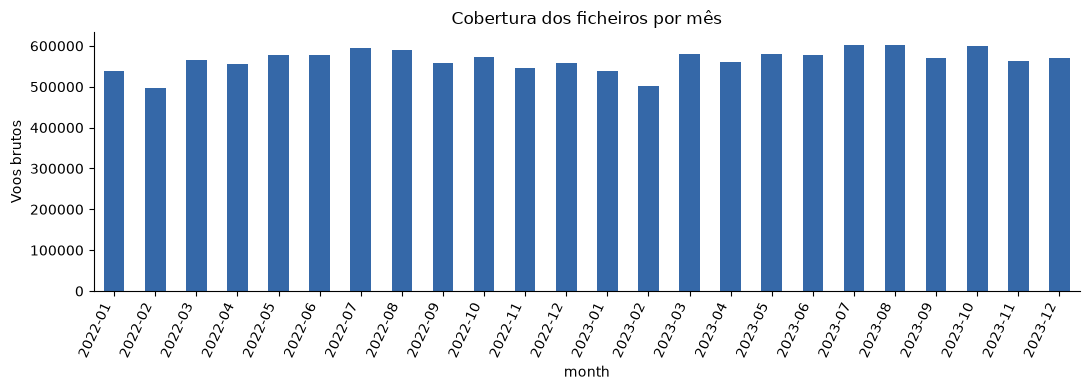

Manifesto: complete | ZIPs mensais: 24
Totais declarados por ano: {2022: 6729125, 2023: 6847899}


In [4]:
def table(name):
    return pd.read_csv(REPORTS / f"{name}.csv", keep_default_na=False)

coverage = table("monthly_coverage")
expected_months = set(pd.period_range("2022-01", "2023-12", freq="M").astype(str))
observed_months = set(coverage["month"]) - {"invalid_date"}
print("Meses em falta:", sorted(expected_months - observed_months))
print("Períodos inesperados:", sorted(observed_months - expected_months))
display(pd.DataFrame(summary["schemas"])[["file", "missing_policy_columns", "unexpected_columns"]])
plot = coverage.loc[coverage["month"].ne("invalid_date")].set_index("month")
plot["rows_raw"].plot.bar(color="#3568a8", ylabel="Voos brutos", title="Cobertura dos ficheiros por mês")
plt.xticks(rotation=65, ha="right")
plt.tight_layout()
plt.show()
manifest_path = DATA_DIR / "bts_download_manifest.json"
if manifest_path.exists():
    manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
    print("Manifesto:", manifest.get("status"), "| ZIPs mensais:", len(manifest.get("monthly_files", [])))
    print("Totais declarados por ano:", {year: sum(item.get("data_rows", 0) for item in manifest.get("monthly_files", []) if item.get("year") == year) for year in [2022, 2023]})


## 5. População elegível: quantos registos podemos utilizar?

O enunciado exclui voos cancelados, desviados e sem atraso de chegada válido. Aplicamos os filtros sequencialmente, para não contar duas vezes exclusões sobrepostas:

1. todos os registos;
2. `Cancelled == 0`;
3. também `Diverted == 0`;
4. também `ArrDelay` numérico e finito.

Flags ausentes ou fora de {0, 1} são problemas a investigar. Não assumimos que uma flag ausente é zero. Criar o alvo com informação observada é correto; fornecer esse alvo ao modelo como feature não seria.


In [5]:
eligibility = table("eligibility")
eligibility["excluídos_nesta_etapa"] = -eligibility["rows"].diff().fillna(0).astype(int)
display(eligibility)
assert int(eligibility.iloc[-1]["rows"]) == summary["rows_eligible"]
print(f"Elegíveis: {summary['rows_eligible']:,} / {summary['rows_raw']:,} ({100 * summary['rows_eligible'] / summary['rows_raw']:.2f}%).")


,stage,rows,excluídos_nesta_etapa
0,01_raw,13577024,0
1,02_cancelled_eq_0,13307795,269229
2,03_also_diverted_eq_0,13275417,32378
3,04_also_finite_arrdelay,13275415,2


Elegíveis: 13,275,415 / 13,577,024 (97.78%).


## 6. Valores ausentes: distinguir ausência estrutural de falha

Nesta auditoria, vazio ou apenas espaços conta como ausente. Textos literais como `NA` e `NULL` são preservados: os controlos numéricos e de datas identificam valores malformados nos campos verificados. Zero não é ausência, e atraso negativo também não.

Comparamos a população bruta com a elegível. Muitos campos de desvios, cancelamento e atribuição de atraso podem estar vazios porque não se aplicam. Não devem ser imputados só para preencher uma tabela. Nos oito inputs iniciais, qualquer ausência merece uma política explícita de preparação/inferência.


,column,rows_raw,missing_raw,missing_pct_raw,rows_eligible,missing_eligible,missing_pct_eligible,distinct_nonmissing_raw,constant_nonmissing_raw
109,Unnamed: 109,13577024,13577024,100.000000,13275415,13275415,100.0,0,False
93,Div4Airport,13577024,13577024,100.000000,13275415,13275415,100.0,0,False
95,Div4AirportSeqID,13577024,13577024,100.000000,13275415,13275415,100.0,0,False
96,Div4WheelsOn,13577024,13577024,100.000000,13275415,13275415,100.0,0,False
97,Div4TotalGTime,13577024,13577024,100.000000,13275415,13275415,100.0,0,False
98,Div4LongestGTime,13577024,13577024,100.000000,13275415,13275415,100.0,0,False
99,Div4WheelsOff,13577024,13577024,100.000000,13275415,13275415,100.0,0,False
100,Div4TailNum,13577024,13577024,100.000000,13275415,13275415,100.0,0,False
101,Div5Airport,13577024,13577024,100.000000,13275415,13275415,100.0,0,False
94,Div4AirportID,13577024,13577024,100.000000,13275415,13275415,100.0,0,False


,feature,missing_raw,missing_pct_raw,missing_eligible,missing_pct_eligible,distinct_nonmissing_raw
5,FlightDate,0,0.000000,0,0.0,730
6,Reporting_Airline,0,0.000000,0,0.0,17
14,Origin,0,0.000000,0,0.0,372
23,Dest,0,0.000000,0,0.0,373
29,CRSDepTime,0,0.000000,0,0.0,1389
40,CRSArrTime,0,0.000000,0,0.0,1437
50,CRSElapsedTime,5,0.000037,0,0.0,646
54,Distance,0,0.000000,0,0.0,1648


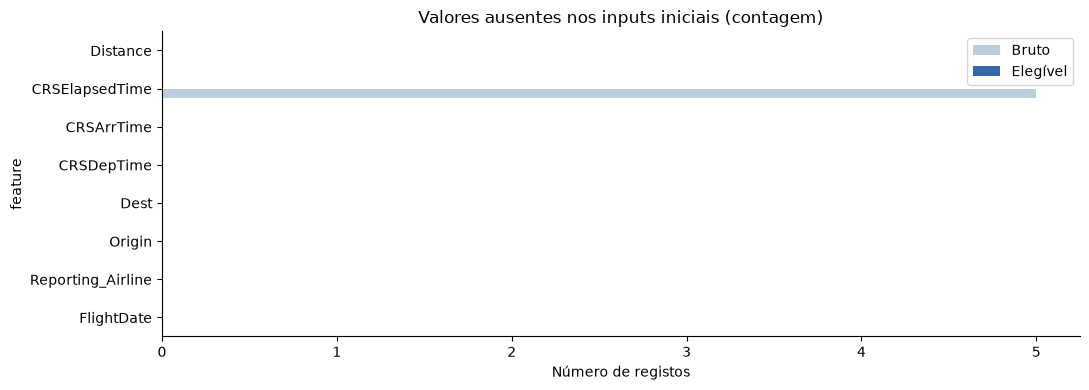

,column,rows_raw,missing_raw,distinct_nonmissing_raw
109,Unnamed: 109,13577024,13577024,0


Coluna final totalmente vazia: True


In [6]:
columns = table("columns")
feature_review = table("feature_review")
display(columns.sort_values("missing_pct_raw", ascending=False).head(20))
baseline = feature_review.loc[feature_review["initial_baseline"].astype(str).str.lower().eq("true")]
display(baseline[["feature", "missing_raw", "missing_pct_raw", "missing_eligible", "missing_pct_eligible", "distinct_nonmissing_raw"]])
baseline.set_index("feature")[["missing_raw", "missing_eligible"]].rename(
    columns={"missing_raw": "Bruto", "missing_eligible": "Elegível"}).plot.barh(
    title="Valores ausentes nos inputs iniciais (contagem)", xlabel="Número de registos", color=["#bccddd", "#3568a8"])
plt.tight_layout()
plt.show()
unnamed = columns[columns["column"].str.startswith("Unnamed:")]
if not unnamed.empty:
    display(unnamed[["column", "rows_raw", "missing_raw", "distinct_nonmissing_raw"]])
    print("Coluna final totalmente vazia:", bool((unnamed["rows_raw"] == unnamed["missing_raw"]).all()))


## 7. Consistência de datas, horários e campos redundantes

Verificamos o calendário face a `FlightDate`; flags binárias; horários previstos em HHMM; duração/distância positivas; e coerência dos indicadores de atraso com o atraso numérico.

`2400` é aceite como representação de meia-noite, mas `2360` e `1261` são inválidos. Converter HHMM em minutos não é dividir por 100. Não subtrair diretamente horas locais de origem e destino para estimar a duração: existem fusos e mudanças de dia.

Os controlos de atraso real servem apenas para auditar a fonte. Esses campos continuam proibidos em X. Uma violação é um sinal para investigar, não uma instrução automática para eliminar o voo. Os denominadores e o âmbito de cada controlo estão na tabela.


In [7]:
checks = table("checks")
display(checks.sort_values(["violations", "check"], ascending=[False, True]))
print("Controlos com violações:", int((checks["violations"] > 0).sum()))
display(table("numeric_summary"))


,check,rows_checked,violations,violation_pct
5,CRSElapsedTime_missing_or_nonpositive_eligible,13275415,5,0.000038
0,ArrDel15_inconsistent,13275415,0,0.000000
1,ArrDelayMinutes_inconsistent,13275415,0,0.000000
2,ArrDelay_nonempty_invalid_numeric,13275415,0,0.000000
3,CRSArrTime_missing_or_invalid_HHMM_eligible,13275415,0,0.000000
4,CRSDepTime_missing_or_invalid_HHMM_eligible,13275415,0,0.000000
6,Cancelled_missing_or_not_binary,13577024,0,0.000000
7,DayOfWeek_inconsistent_with_FlightDate,13577024,0,0.000000
8,DayofMonth_inconsistent_with_FlightDate,13577024,0,0.000000
9,DepDel15_inconsistent,13315147,0,0.000000


Controlos com violações: 1


,column,finite_count_raw,mean_raw,std_raw,min_raw,max_raw
0,ArrDelay,13275415,6.828148,55.754490,-119.0,4405.0
1,DepDelay,13315147,12.442202,53.956864,-99.0,4413.0
2,Distance,13577024,824.713003,597.509439,21.0,5095.0
3,CRSElapsedTime,13577019,144.427378,72.723924,-272.0,1425.0
4,ActualElapsedTime,13275415,138.926267,72.664340,14.0,795.0
5,AirTime,13275415,113.812438,70.519394,6.0,727.0
6,TaxiIn,13304446,7.990824,6.545763,1.0,290.0
7,TaxiOut,13309230,17.135810,9.259686,1.0,269.0


### 7.1 Investigar durações previstas não positivas

Na primeira execução completa foram encontrados **5 voos elegíveis com CRSElapsedTime não positivo**. Isto é diferente de ausência: nos inputs iniciais não havia valores vazios entre os elegíveis, mas ainda existem valores inválidos.

A célula seguinte faz uma passagem adicional apenas pelas colunas necessárias e guarda no máximo 20 exemplos, sem expor o alvo na tabela. O número de registo é a posição do voo no CSV, começando em 1 após o cabeçalho. A cache de exemplos pode ser apagada para a reconstruir; não altera os dados originais.

A duração prevista não deve ser reconstruída por simples subtração das horas locais. Na preparação decidiremos, com justificação, entre colocar estes registos em quarentena ou marcar a duração inválida como ausente e aplicar uma política aprendida só no treino. Os valores extremos de atraso também não serão eliminados só por serem grandes.


In [8]:
example_path = REPORTS / "invalid_scheduled_duration_examples.csv"
check_name = "CRSElapsedTime_missing_or_nonpositive_eligible"
problem_count = int(checks.set_index("check").loc[check_name, "violations"])
examples_are_current = (example_path.exists() and example_path.stat().st_mtime_ns
                        >= (REPORTS / "summary.json").stat().st_mtime_ns)
if problem_count and not examples_are_current:
    selected = ["FlightDate", "Reporting_Airline", "Flight_Number_Reporting_Airline", "Origin", "Dest",
                "CRSDepTime", "CRSArrTime", "CRSElapsedTime", "Distance", "Cancelled", "Diverted", "ArrDelay"]
    examples = []
    collected = 0
    for path in FILES:
        with pd.read_csv(path, usecols=selected, dtype=str, keep_default_na=False,
                         chunksize=200_000) as reader:
            for chunk in reader:
                duration = pd.to_numeric(chunk["CRSElapsedTime"], errors="coerce").replace([float("inf"), -float("inf")], float("nan"))
                arrival = pd.to_numeric(chunk["ArrDelay"], errors="coerce").replace([float("inf"), -float("inf")], float("nan"))
                mask = (pd.to_numeric(chunk["Cancelled"], errors="coerce").eq(0)
                        & pd.to_numeric(chunk["Diverted"], errors="coerce").eq(0)
                        & arrival.notna() & (duration.isna() | duration.le(0)))
                found = chunk.loc[mask].head(20 - collected).drop(columns=["ArrDelay"])
                found.insert(0, "source_record_1based", found.index + 1)
                found.insert(0, "source_file", path.name)
                if not found.empty:
                    examples.append(found)
                    collected += len(found)
                if collected >= 20:
                    break
        if collected >= 20:
            break
    if examples:
        pd.concat(examples, ignore_index=True).to_csv(example_path, index=False)
if problem_count and example_path.exists():
    display(pd.read_csv(example_path, dtype=str, keep_default_na=False))
else:
    print("Sem exemplos disponíveis; consultar o controlo de duração e o âmbito desta execução.")


,source_file,source_record_1based,FlightDate,Reporting_Airline,Flight_Number_Reporting_Airline,Origin,Dest,CRSDepTime,CRSArrTime,Cancelled,Diverted,CRSElapsedTime,Distance
0,flights_2022.csv,388369,2022-01-21,YX,3401,BNA,EWR,0600,0922,0.00,0.00,-48.00,748.00
1,flights_2022.csv,5219236,2022-10-14,YX,5769,IND,LGA,0605,0811,0.00,0.00,-44.00,660.00
2,flights_2022.csv,5219247,2022-10-23,YX,5690,PIT,BOS,0825,0804,0.00,0.00,-36.00,496.00
3,flights_2022.csv,6449167,2022-12-06,YX,5737,PIT,BOS,0605,0805,0.00,0.00,-85.00,496.00
4,flights_2023.csv,1465111,2023-03-23,YX,5784,JFK,PWM,2240,2235,0.00,0.00,-5.00,273.00


## 8. Repetições de uma chave candidata de operação

Chave proposta: data, companhia reportante, número de voo, origem, destino e hora prevista de partida. O número de voo e a hora são normalizados numericamente. A contagem é exata para esta chave, em todo o conjunto e entre blocos, com SQLite temporário.

Uma repetição pode indicar duplicação, revisão de um registo ou uma limitação da própria chave. Não prova que duas linhas completas sejam iguais e não autoriza apagá-las automaticamente. Registos sem chave válida são contabilizados à parte. A igualdade exata de todas as 109 colunas não é verificada nesta versão.


In [9]:
duplicate_info = summary["duplicates"]
display(pd.DataFrame([{k: v for k, v in duplicate_info.items() if k not in ["key_fields", "note"]}]))
print(duplicate_info["note"])


,checked,scope,rows_with_key,rows_without_valid_key,unique_keys,repeated_key_groups,extra_rows_with_repeated_key
0,True,raw rows with a valid complete candidate key,13577024,0,13577024,0,0


Repeated candidate keys are not proof of identical records; no records were removed. Exact full-row duplication is not assessed.


## 9. Criar e compreender as três classes, preservando o teste final

`on_time`: ArrDelay < 15; `moderate_delay`: 15 <= ArrDelay < 60; `severe_delay`: ArrDelay >= 60. Incluímos chegadas antecipadas em on_time e nunca transformamos alvo ausente em zero.

Reservamos provisoriamente julho–dezembro de 2023 para teste. Por omissão, as distribuições do alvo mostradas abaixo usam apenas janeiro de 2022 a junho de 2023. Os relatórios completos incluem agregados do conjunto inteiro para auditoria, mas não devem ser usados para escolher features, hiperparâmetros ou balanceamento com base no holdout.

Ainda não há split materializado nem classificador. A decisão das datas deve ficar congelada antes das experiências de modelação.


,count,pct
class,,
on_time,7707178,78.548724
moderate_delay,1403428,14.303222
severe_delay,701365,7.148054


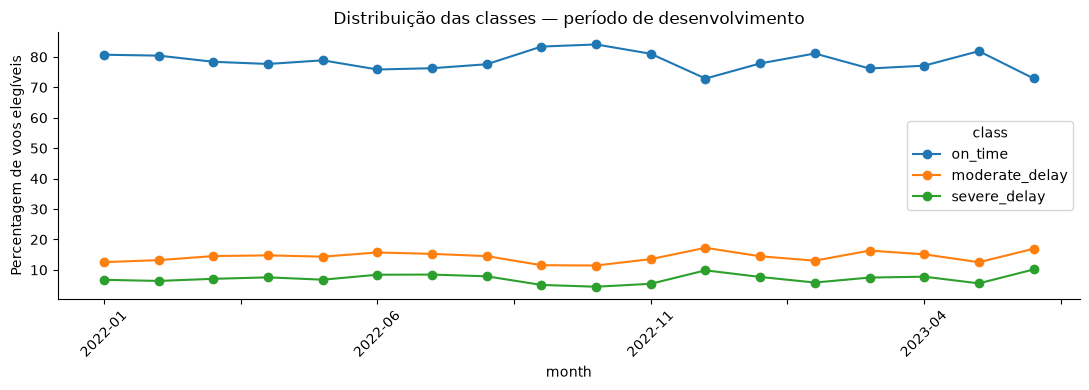

In [10]:
monthly_classes = table("classes_by_month")
SHOW_HOLDOUT_LABELS = False
valid_month = monthly_classes["month"].str.fullmatch(r"202[23]-\d{2}")
mask = valid_month if SHOW_HOLDOUT_LABELS else valid_month & monthly_classes["month"].le("2023-06")
visible = monthly_classes.loc[mask]
class_order = ["on_time", "moderate_delay", "severe_delay"]
counts = visible.groupby("class")["count"].sum().reindex(class_order, fill_value=0)
display(pd.DataFrame({"count": counts, "pct": 100 * counts / counts.sum()}))
by_month = visible.pivot(index="month", columns="class", values="count").reindex(columns=class_order).fillna(0)
shares = by_month.div(by_month.sum(axis=1), axis=0) * 100
shares.plot(marker="o", ylabel="Percentagem de voos elegíveis", title="Distribuição das classes — período de desenvolvimento")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
assert int(table("classes")["count"].sum()) == summary["rows_eligible"]


## 10. Features: admissibilidade temporal não é importância preditiva

A política documental distingue candidatos, campo condicional, exclusões, alvo, filtros e campo possivelmente constante. Os 35 candidatos não são 35 variáveis já selecionadas: há várias codificações da mesma companhia, aeroporto e calendário.

O baseline propõe oito entradas brutas: FlightDate, Reporting_Airline, Origin, Dest, CRSDepTime, CRSArrTime, CRSElapsedTime e Distance. Tail_Number fica excluído até existir prova de disponibilidade pré-partida. Flights deve ser verificado quanto à variação.

DepDelay, DepTime, ArrTime, AirTime, atrasos por causa e informação de desvios são observações da operação, posteriores ao corte exigido. Não usar sequer os seus padrões de ausência como preditores. ArrDelay pertence apenas a y; Cancelled e Diverted pertencem ao filtro offline.

A política não é ainda um pipeline que imponha a lista permitida. A preparação futura deverá selecionar X explicitamente e reutilizar as mesmas transformações na API. Confirmar aliases como FlightDate / FL_DATE com o colega responsável pela inferência.


In [11]:
display(feature_review.groupby("role").size().rename("n_features").to_frame())
display(baseline[["feature", "role", "reason"]])
print("Campos constantes entre os valores não ausentes (âmbito bruto):")
display(columns.loc[columns["constant_nonmissing_raw"].astype(str).str.lower().eq("true"),
                    ["column", "distinct_nonmissing_raw", "missing_pct_raw"]])
print("Flights:")
display(table("top_values").query("column == 'Flights'"))


,n_features
role,
candidate,35
conditional,1
exclude,69
filter,2
target,1
uninformative,1


,feature,role,reason
5,FlightDate,candidate,Data prevista do voo. Usar para splits e extra...
6,Reporting_Airline,candidate,Identificação da companhia. Escolher uma repre...
14,Origin,candidate,Código do aeroporto planeado. Escolher código ...
23,Dest,candidate,Código do aeroporto planeado. Escolher código ...
29,CRSDepTime,candidate,"Hora prevista de partida, conhecida no plano. ..."
40,CRSArrTime,candidate,"Hora prevista de chegada, conhecida antes da p..."
50,CRSElapsedTime,candidate,Duração prevista. Admissível; não confundir co...
54,Distance,candidate,Característica da rota planeada. Candidato; te...


Campos constantes entre os valores não ausentes (âmbito bruto):


,column,distinct_nonmissing_raw,missing_pct_raw
53,Flights,1,0.000000
91,Div3WheelsOff,1,99.999993
92,Div3TailNum,1,99.999993


Flights:


,column,value,count
248,Flights,1.00,13577024


## 11. Ler os resultados e decidir o próximo passo

A tabela seguinte resume os factos calculados. As decisões de limpeza exigem investigar cada ocorrência e documentar a regra; não há correções silenciosas nem remoções de registos neste notebook.

A auditoria não mede causalidade, importância preditiva, disponibilidade histórica efetiva de um campo, nem desempenho de modelos. Uma categoria rara ou um valor extremo não é automaticamente um erro. Uma diferença entre anos também pode ser uma mudança real da operação.


In [12]:
facts = {
    "Linhas brutas": summary["rows_raw"],
    "Linhas elegíveis": summary["rows_eligible"],
    "Linhas excluídas pela regra do enunciado": summary["rows_excluded"],
    "Meses esperados em falta": len(expected_months - observed_months),
    "Controlos com violações": int((checks["violations"] > 0).sum()),
    "Inputs iniciais com ausentes na população elegível": int((pd.to_numeric(baseline["missing_eligible"]) > 0).sum()),
    "Grupos com chave candidata repetida": duplicate_info.get("repeated_key_groups", "não verificado"),
}
display(pd.DataFrame(facts.items(), columns=["Indicador", "Resultado"]))
print("Limitações explícitas:")
for item in summary["limitations"]:
    print("-", item)
print("Relatórios disponíveis:")
for path in sorted(REPORTS.glob("*.csv")):
    print("-", path.name)


,Indicador,Resultado
0,Linhas brutas,13577024
1,Linhas elegíveis,13275415
2,Linhas excluídas pela regra do enunciado,301609
3,Meses esperados em falta,0
4,Controlos com violações,1
5,Inputs iniciais com ausentes na população eleg...,0
6,Grupos com chave candidata repetida,0


Limitações explícitas:
- No proof of when historical fields became available before departure.
- No model importance or causal conclusions.
- No exact full-row duplicate check.
- Candidate operation keys are not guaranteed unique flight identifiers.
- Numeric ranges are checks, not automatic deletion rules.
- Exact cardinality counters grow with the number of distinct values; only CSV reading is bounded by chunksize.
Relatórios disponíveis:
- checks.csv
- classes.csv
- classes_by_month.csv
- classes_by_subgroup.csv
- columns.csv
- eligibility.csv
- feature_review.csv
- invalid_scheduled_duration_examples.csv
- monthly_coverage.csv
- numeric_summary.csv
- top_values.csv


## 12. Próximas decisões e rastreabilidade

1. Rever controlos com violações e documentar tratamento de datas/horários inválidos e inputs ausentes.
2. Confirmar o contrato de campos da API e congelar a lista permitida de features.
3. Implementar preparação reproduzível e produzir Parquet, preservando os CSV originais.
4. Materializar folds por datas inteiras: treino jan.–set. 2022 / validação out.–dez. 2022; treino 2022 / validação jan.–mar. 2023; treino até mar. 2023 / validação abr.–jun. 2023. Teste reservado: jul.–dez. 2023.
5. Ajustar imputação/encoding/seleção só no treino de cada fold e comparar um baseline maioritário com um primeiro modelo.
6. Registar código e decisões no Git, dados no DVC e experiências/modelos no MLflow. Este notebook ainda não configura serviços remotos.

**Reproduzir no terminal**, a partir da raiz:

```bash
python scripts/audit_data.py
python -m unittest discover -s tests -v
```

**Teste rápido do programa**, sem conclusões estatísticas: `python scripts/audit_data.py --max-chunks 1 --chunksize 1000 --skip-duplicates`. Só lê o início de cada ano; os resultados parciais ficam por omissão em `reports/generated/data_audit_smoke/`.

**Referências:** enunciado `mlops_project_flight.v1.1.pdf` na raiz; política autocontida dos 109 campos e respetivas justificações em `configs/feature_policy.csv`. O manifesto do download e os SHA-256 dos CSV permitem identificar a fonte analisada. As saídas guardadas no notebook são um retrato dessa execução; voltar a executar as células valida a correspondência com os ficheiros atuais.
